# 05 - Forecast uncertainty and safety-stock levels

This notebook estimates uncertainty around seven-day demand forecasts and translates upper demand quantiles into safety-stock levels.

The calculation uses a seven-day replenishment lead time and a weekly review cycle. These are project assumptions because M5 does not provide Walmart's supplier lead times or replenishment rules. Inventory outcomes are not simulated in this notebook.

## 1. Load prepared data and selected baseline models

Notebook 04 selected one point-forecast baseline for each series using validation MAE. This notebook uses those selections while keeping final-test sales unavailable.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "uncertainty_safety_stock"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_END = 1885
VALIDATION_START = 1886
VALIDATION_END = 1913
LEAD_TIME_DAYS = 7
SERVICE_TARGETS = [0.80, 0.90, 0.95]

metadata = pd.read_csv(PROCESSED_DATA_DIR / "selected_series_metadata.csv")
development = pd.read_csv(
    PROCESSED_DATA_DIR / "selected_series_development.csv",
    parse_dates=["date"],
)
model_selection = pd.read_csv(PROCESSED_DATA_DIR / "forecast_model_selection.csv")

series_order = metadata["series_key"].tolist()
development_wide = (
    development.pivot(index="series_key", columns="day_number", values="sales")
    .reindex(index=series_order, columns=range(1, VALIDATION_END + 1))
)

assert len(model_selection) == 12
assert development_wide.notna().all().all()
assert development_wide.columns.max() == VALIDATION_END
assert set(model_selection["series_key"]) == set(series_order)

display(model_selection[["series_key", "profile", "selected_model", "mae"]].round(3))

,series_key,profile,selected_model,mae
0,FOODS_1_096_WI_2,weekly_pattern,mean_28,9.531
1,FOODS_2_254_TX_3,intermittent,mean_28,0.832
2,FOODS_2_255_CA_4,variable,mean_28,0.872
3,FOODS_3_586_CA_1,stable,seasonal_naive_7,8.607
4,HOBBIES_1_209_TX_1,variable,mean_28,1.990
5,HOBBIES_1_323_TX_2,weekly_pattern,mean_28,1.684
6,HOBBIES_1_345_WI_1,stable,mean_28,1.949
7,HOBBIES_2_110_CA_3,intermittent,seasonal_naive_7,0.000
8,HOUSEHOLD_1_161_WI_3,intermittent,seasonal_naive_7,0.750
9,HOUSEHOLD_1_191_CA_2,weekly_pattern,last_value,3.679


## 2. Seven-day forecasting rule

One small helper applies the selected baseline at a forecast origin. It is reused for training-error calibration, validation checks, and the safety-stock calculation.

- last value repeats the latest observation;
- seasonal naive repeats the latest seven-day pattern; and
- 28-day mean repeats the latest 28-day average.

In [2]:
def baseline_forecast(history, model, horizon):
    # Use only observations available at the forecast origin.
    if model == "last_value":
        forecast = np.repeat(history[-1], horizon)
    elif model == "seasonal_naive_7":
        forecast = np.resize(history[-7:], horizon)
    elif model == "mean_28":
        forecast = np.repeat(history[-28:].mean(), horizon)
    else:
        raise ValueError(f"Unknown model: {model}")

    return np.maximum(forecast.astype("float64"), 0.0)

## 3. Calibrate seven-day forecast errors on training data

The calibration period uses 52 weekly forecast origins from the latest training year. At each origin, the model sees only earlier observations and predicts the next seven-day total.

The calibration error is:

`actual seven-day sales - forecast seven-day sales`

Positive errors mean demand was higher than the point forecast. Upper error quantiles therefore provide an empirical uncertainty buffer.

In [3]:
calibration_rows = []

for series_key in series_order:
    training_history = development_wide.loc[series_key, range(1, TRAIN_END + 1)].to_numpy(dtype="float64")
    selected_model = model_selection.loc[
        model_selection["series_key"] == series_key, "selected_model"
    ].iat[0]
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]

    first_origin = len(training_history) - 364
    calibration_origins = range(first_origin, len(training_history) - LEAD_TIME_DAYS + 1, 7)

    for origin in calibration_origins:
        history_at_origin = training_history[:origin]
        actual_lead_time = training_history[origin : origin + LEAD_TIME_DAYS]
        forecast_lead_time = baseline_forecast(
            history_at_origin,
            selected_model,
            LEAD_TIME_DAYS,
        )
        calibration_rows.append(
            {
                "series_key": series_key,
                "profile": profile,
                "selected_model": selected_model,
                "origin_day": origin,
                "actual_seven_day_sales": actual_lead_time.sum(),
                "forecast_seven_day_sales": forecast_lead_time.sum(),
                "forecast_error": actual_lead_time.sum() - forecast_lead_time.sum(),
            }
        )

calibration_errors = pd.DataFrame(calibration_rows)

error_quantiles = (
    calibration_errors.groupby(["series_key", "profile", "selected_model"])["forecast_error"]
    .quantile([0.05, 0.10, 0.50, 0.80, 0.90, 0.95])
    .unstack()
    .reset_index()
    .rename(
        columns={
            0.05: "error_q05",
            0.10: "error_q10",
            0.50: "error_q50",
            0.80: "error_q80",
            0.90: "error_q90",
            0.95: "error_q95",
        }
    )
)

calibration_check = calibration_errors.groupby("series_key").size()
display(error_quantiles.round(2))

assert len(calibration_errors) == 12 * 52
assert calibration_check.eq(52).all()
assert error_quantiles[["error_q05", "error_q10", "error_q50", "error_q80", "error_q90", "error_q95"]].notna().all().all()

,series_key,profile,selected_model,error_q05,error_q10,error_q50,error_q80,error_q90,error_q95
0,FOODS_1_096_WI_2,weekly_pattern,mean_28,-72.66,-41.12,12.37,53.40,69.30,88.21
1,FOODS_2_254_TX_3,intermittent,mean_28,-2.50,-1.97,0.00,1.15,2.47,3.86
2,FOODS_2_255_CA_4,variable,mean_28,-8.06,-5.97,-1.12,2.95,7.12,11.91
3,FOODS_3_586_CA_1,stable,seasonal_naive_7,-61.80,-43.30,-0.50,37.80,58.30,64.90
4,HOBBIES_1_209_TX_1,variable,mean_28,-9.36,-7.40,-0.50,5.75,8.95,11.17
5,HOBBIES_1_323_TX_2,weekly_pattern,mean_28,-7.59,-6.25,-0.12,4.40,6.20,7.09
6,HOBBIES_1_345_WI_1,stable,mean_28,-8.20,-7.50,1.50,4.20,5.50,7.70
7,HOBBIES_2_110_CA_3,intermittent,seasonal_naive_7,-3.00,-2.90,0.00,1.00,2.90,3.00
8,HOUSEHOLD_1_161_WI_3,intermittent,seasonal_naive_7,-3.00,-2.00,0.00,2.00,2.90,3.00
9,HOUSEHOLD_1_191_CA_2,weekly_pattern,last_value,-116.90,-106.60,-38.50,0.00,17.80,26.40


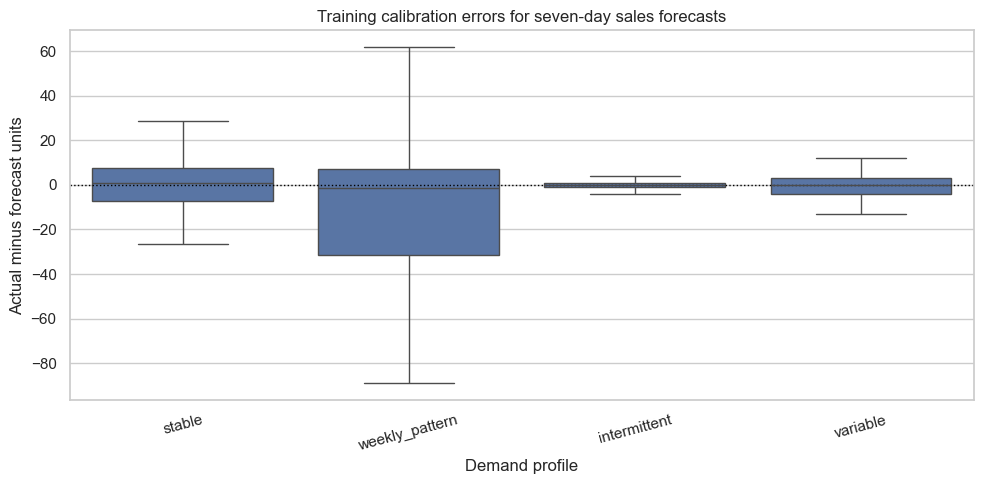

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=calibration_errors,
    x="profile",
    y="forecast_error",
    order=["stable", "weekly_pattern", "intermittent", "variable"],
    showfliers=False,
    ax=ax,
)
ax.axhline(0, color="black", linewidth=1, linestyle=":")
ax.set(
    title="Training calibration errors for seven-day sales forecasts",
    xlabel="Demand profile",
    ylabel="Actual minus forecast units",
)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "calibration_error_by_profile.png", dpi=300, bbox_inches="tight")
plt.show()

### Calibration interpretation

Errors above zero represent under-forecasting and create positive safety-stock buffers at upper quantiles. Errors below zero represent over-forecasting. The profile distributions have different spreads, so each series keeps its own empirical error quantiles.

## 4. Check uncertainty on the validation period

The 28-day validation period is evaluated as four weekly review cycles. At each weekly origin, the forecast may use observations from earlier validation weeks, which represents a rolling operational forecast.

The central 80% interval uses the 10th and 90th calibration-error quantiles. The central 90% interval uses the 5th and 95th quantiles. Coverage is the percentage of actual seven-day totals inside each interval.

In [5]:
validation_week_rows = []

for series_key in series_order:
    full_history = development_wide.loc[series_key].to_numpy(dtype="float64")
    selected_model = model_selection.loc[
        model_selection["series_key"] == series_key, "selected_model"
    ].iat[0]
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]
    quantiles = error_quantiles[error_quantiles["series_key"] == series_key].iloc[0]

    for validation_week in range(4):
        origin = TRAIN_END + validation_week * LEAD_TIME_DAYS
        history_at_origin = full_history[:origin]
        actual_lead_time = full_history[origin : origin + LEAD_TIME_DAYS]
        point_forecast = baseline_forecast(history_at_origin, selected_model, LEAD_TIME_DAYS).sum()
        actual_total = actual_lead_time.sum()

        lower_80 = max(0.0, point_forecast + quantiles["error_q10"])
        upper_80 = max(lower_80, point_forecast + quantiles["error_q90"])
        lower_90 = max(0.0, point_forecast + quantiles["error_q05"])
        upper_90 = max(lower_90, point_forecast + quantiles["error_q95"])

        row = {
            "series_key": series_key,
            "profile": profile,
            "selected_model": selected_model,
            "validation_week": validation_week + 1,
            "origin_day": origin,
            "actual_seven_day_sales": actual_total,
            "point_forecast": point_forecast,
            "lower_80": lower_80,
            "upper_80": upper_80,
            "lower_90": lower_90,
            "upper_90": upper_90,
            "covered_80": lower_80 <= actual_total <= upper_80,
            "covered_90": lower_90 <= actual_total <= upper_90,
        }

        for target in SERVICE_TARGETS:
            quantile_forecast = max(0.0, point_forecast + quantiles[f"error_q{int(target * 100):02d}"])
            difference = actual_total - quantile_forecast
            row[f"demand_q{int(target * 100):02d}"] = quantile_forecast
            row[f"pinball_q{int(target * 100):02d}"] = max(
                target * difference,
                (target - 1) * difference,
            )

        validation_week_rows.append(row)

validation_uncertainty = pd.DataFrame(validation_week_rows)

coverage_summary = pd.DataFrame(
    {
        "interval": ["Central 80%", "Central 90%"],
        "target_coverage_pct": [80.0, 90.0],
        "observed_coverage_pct": [
            100 * validation_uncertainty["covered_80"].mean(),
            100 * validation_uncertainty["covered_90"].mean(),
        ],
        "mean_width_units": [
            (validation_uncertainty["upper_80"] - validation_uncertainty["lower_80"]).mean(),
            (validation_uncertainty["upper_90"] - validation_uncertainty["lower_90"]).mean(),
        ],
    }
)

pinball_summary = pd.DataFrame(
    {
        "demand_quantile": SERVICE_TARGETS,
        "mean_pinball_loss": [
            validation_uncertainty[f"pinball_q{int(target * 100):02d}"].mean()
            for target in SERVICE_TARGETS
        ],
    }
)

display(coverage_summary.round(2))
display(pinball_summary.round(3))
assert len(validation_uncertainty) == 12 * 4

,interval,target_coverage_pct,observed_coverage_pct,mean_width_units
0,Central 80%,80.0,79.17,34.81
1,Central 90%,90.0,85.42,45.42


,demand_quantile,mean_pinball_loss
0,0.80,3.500
1,0.90,2.278
2,0.95,1.474


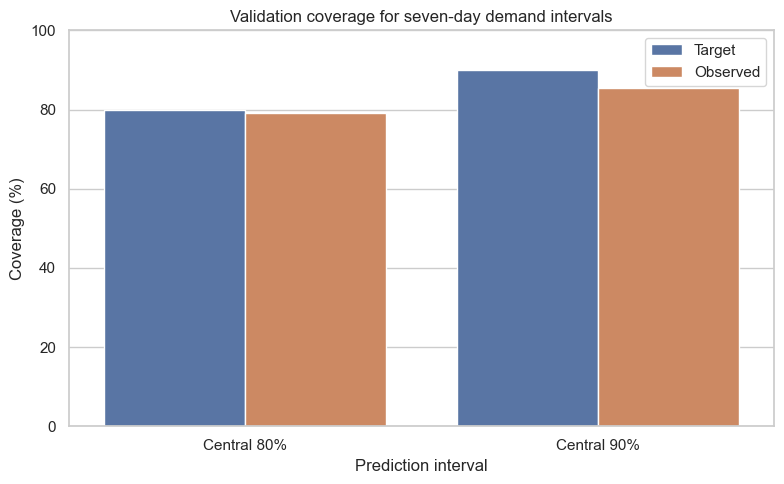

In [6]:
coverage_plot = coverage_summary.melt(
    id_vars="interval",
    value_vars=["target_coverage_pct", "observed_coverage_pct"],
    var_name="coverage_type",
    value_name="coverage_pct",
)
coverage_plot["coverage_type"] = coverage_plot["coverage_type"].map({
    "target_coverage_pct": "Target",
    "observed_coverage_pct": "Observed",
})

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=coverage_plot, x="interval", y="coverage_pct", hue="coverage_type", ax=ax)
ax.set(
    title="Validation coverage for seven-day demand intervals",
    xlabel="Prediction interval",
    ylabel="Coverage (%)",
    ylim=(0, 100),
)
ax.legend(title="")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "validation_interval_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

### Validation interpretation

Observed coverage should be read with care because the sample has only 48 weekly outcomes and the same validation period was used to select point-forecast methods. Interval width gives the amount of uncertainty required for that coverage. Pinball loss evaluates each upper demand quantile by penalizing under-forecasting more heavily at higher targets.

The untouched final test period will provide the later evaluation after the full forecasting and inventory design is fixed.

## 5. Calculate safety stock for the next seven-day period

Each selected model is refit by giving it all development observations through `d_1913`. The expected lead-time demand is its seven-day point forecast.

For a target quantile `q`:

`safety stock = max(0, q demand forecast - expected lead-time demand)`

The resulting units are planning inputs for notebook 06. They are not measured Walmart inventory levels or proven service outcomes.

In [7]:
safety_stock_rows = []

for series_key in series_order:
    full_history = development_wide.loc[series_key].to_numpy(dtype="float64")
    selected_model = model_selection.loc[
        model_selection["series_key"] == series_key, "selected_model"
    ].iat[0]
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]
    quantiles = error_quantiles[error_quantiles["series_key"] == series_key].iloc[0]
    expected_lead_time_demand = baseline_forecast(
        full_history,
        selected_model,
        LEAD_TIME_DAYS,
    ).sum()

    for target in SERVICE_TARGETS:
        demand_quantile = max(
            0.0,
            expected_lead_time_demand + quantiles[f"error_q{int(target * 100):02d}"],
        )
        safety_stock_rows.append(
            {
                "series_key": series_key,
                "profile": profile,
                "selected_model": selected_model,
                "lead_time_days": LEAD_TIME_DAYS,
                "target_quantile": target,
                "expected_lead_time_demand": expected_lead_time_demand,
                "demand_quantile": demand_quantile,
                "safety_stock": max(0.0, demand_quantile - expected_lead_time_demand),
                "order_up_to_level": demand_quantile,
            }
        )

safety_stock = pd.DataFrame(safety_stock_rows)
display(
    safety_stock.pivot_table(
        index=["series_key", "profile", "expected_lead_time_demand"],
        columns="target_quantile",
        values="safety_stock",
    ).round(2)
)

assert len(safety_stock) == 12 * len(SERVICE_TARGETS)
assert safety_stock["safety_stock"].ge(0).all()
assert safety_stock["order_up_to_level"].ge(0).all()

,,target_quantile,0.80,0.90,0.95
series_key,profile,expected_lead_time_demand,,,
FOODS_1_096_WI_2,weekly_pattern,379.50,53.40,69.30,88.21
FOODS_2_254_TX_3,intermittent,6.00,1.15,2.47,3.86
FOODS_2_255_CA_4,variable,4.25,2.95,7.12,11.91
FOODS_3_586_CA_1,stable,268.00,37.80,58.30,64.90
HOBBIES_1_209_TX_1,variable,15.50,5.75,8.95,11.17
HOBBIES_1_323_TX_2,weekly_pattern,22.25,4.40,6.20,7.09
HOBBIES_1_345_WI_1,stable,30.50,4.20,5.50,7.70
HOBBIES_2_110_CA_3,intermittent,0.00,1.00,2.90,3.00
HOUSEHOLD_1_161_WI_3,intermittent,10.00,2.00,2.90,3.00


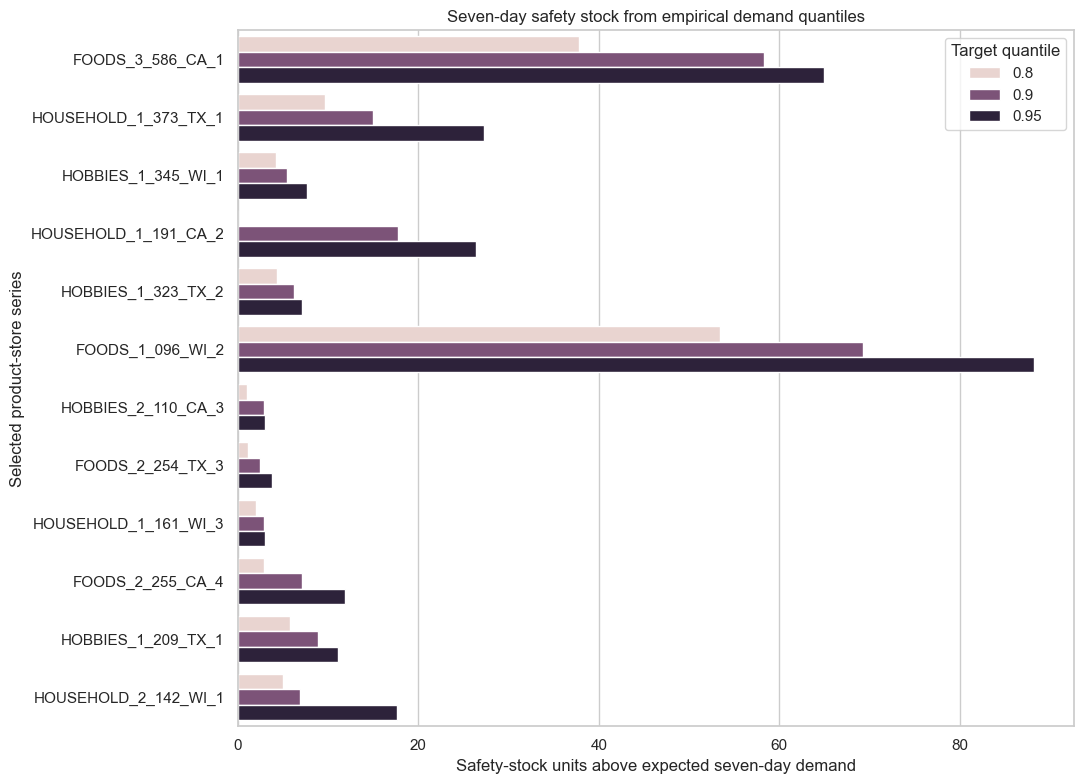

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(
    data=safety_stock,
    y="series_key",
    x="safety_stock",
    hue="target_quantile",
    orient="h",
    ax=ax,
)
ax.set(
    title="Seven-day safety stock from empirical demand quantiles",
    xlabel="Safety-stock units above expected seven-day demand",
    ylabel="Selected product-store series",
)
ax.legend(title="Target quantile")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "safety_stock_by_target.png", dpi=300, bbox_inches="tight")
plt.show()

### Safety-stock interpretation

Higher target quantiles generally require more safety stock because they protect against a larger share of historical under-forecast errors. The amount differs by series because demand scale and forecast-error spread differ.

A zero buffer can occur when the chosen upper error quantile is zero or negative. It does not prove that an item needs no inventory protection. Notebook 06 must compare policy outcomes under the same replenishment and starting-inventory assumptions.

## 6. Save uncertainty and safety-stock outputs

In [9]:
calibration_output = PROCESSED_DATA_DIR / "weekly_uncertainty_calibration.csv"
validation_output = PROCESSED_DATA_DIR / "validation_weekly_probabilistic_forecasts.csv"
safety_stock_output = PROCESSED_DATA_DIR / "safety_stock_levels.csv"

calibration_errors.to_csv(calibration_output, index=False)
validation_uncertainty.to_csv(validation_output, index=False)
safety_stock.to_csv(safety_stock_output, index=False)

saved_outputs = pd.DataFrame(
    {
        "file": [calibration_output.name, validation_output.name, safety_stock_output.name],
        "rows": [len(calibration_errors), len(validation_uncertainty), len(safety_stock)],
        "size_kb": [
            round(calibration_output.stat().st_size / 1024, 1),
            round(validation_output.stat().st_size / 1024, 1),
            round(safety_stock_output.stat().st_size / 1024, 1),
        ],
    }
)
display(saved_outputs)

assert development["day_number"].max() == VALIDATION_END
print("Uncertainty and safety-stock outputs saved without final-test sales.")

,file,rows,size_kb
0,weekly_uncertainty_calibration.csv,624,41.9
1,validation_weekly_probabilistic_forecasts.csv,48,10.1
2,safety_stock_levels.csv,36,3.6


Uncertainty and safety-stock outputs saved without final-test sales.


## 7. Conclusion

The project now has empirical seven-day demand quantiles and safety-stock levels for 80%, 90%, and 95% targets. The estimates use training forecast errors and explicit seven-day replenishment assumptions.

Notebook 06 remains necessary. It will simulate replenishment, compare the probabilistic policy with a fixed buffer, and measure service and inventory outcomes under the same assumptions.